# Intro

**The problem:** About 1 in 3 hotel bookings get cancelled. Late cancellations mean empty rooms and lost money. The hotel wants to know which bookings will likely cancel, so it can act. For example, it could ask for a deposit, send a reminder, or overbook safely.

**The question:** "Can we predict cancellations well enough to save the hotel money, and how much?"

### Imports

In [219]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [220]:
def grouped_bar(total, canc, not_canc, col, order=None, title=""):
    # Turn each table into "value -> count"
    t = total.set_index(col)["count"]
    if order:
        t = t.reindex(order)
    c = canc.set_index(col)["count"].reindex(t.index).fillna(0)
    n = not_canc.set_index(col)["count"].reindex(t.index).fillna(0)

    # Draw 3 bars next to each other for each value
    x = np.arange(len(t))
    w = 0.27
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - w, t.values, w, label="Total")
    ax.bar(x, c.values, w, label="Canceled")
    ax.bar(x + w, n.values, w, label="Not Canceled")
    ax.set_xticks(x)
    ax.set_xticklabels(t.index.astype(str), rotation=45)
    ax.set_title(title)
    ax.set_ylabel("Bookings")
    ax.legend()
    plt.tight_layout()
    plt.show()

### Data Check

In [221]:
df = pd.read_csv("https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2020/2020-02-11/hotels.csv")
df.head()

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [222]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [223]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [224]:
df.describe(include='object')

,hotel,arrival_date_month,meal,country,market_segment,distribution_channel,reserved_room_type,assigned_room_type,deposit_type,customer_type,reservation_status,reservation_status_date
count,119390,119390,119390,118902,119390,119390,119390,119390,119390,119390,119390,119390
unique,2,12,5,177,8,5,10,12,3,4,3,926
top,City Hotel,August,BB,PRT,Online TA,TA/TO,A,A,No Deposit,Transient,Check-Out,2015-10-21
freq,79330,13877,92310,48590,56477,97870,85994,74053,104641,89613,75166,1461


In [225]:
df.shape

(119390, 32)

In [226]:
df.duplicated().sum() # check for duplicates in IDs for example

np.int64(31994)

There can be duplicated rows because there's no ID column. So, there can be similar bookings.

## Column Label:

**lead time**: Number of days that elapsed between the entering date of the booking into the PMS and the arrival date

**meal**: Type of meal booked. Categories are presented in standard hospitality meal packages: Undefined/SC – no meal

**market_segment**: Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour

**agent**: ID of the travel agency that made the booking

**company**: ID of the company/entity that made the booking or responsible for paying the booking. ID is presented instead of

**previous cancellations**: Number of previous bookings that were cancelled by the customer prior to the current booking

**booking changes**: Number of changes/amendments made to the booking from the moment the booking was entered on

In [227]:
df.describe()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,agent,company,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
count,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,119386.000000,119390.000000,119390.000000,119390.000000,119390.000000,119390.000000,103050.000000,6797.000000,119390.000000,119390.000000,119390.000000,119390.000000
mean,0.370416,104.011416,2016.156554,27.165173,15.798241,0.927599,2.500302,1.856403,0.103890,0.007949,0.031912,0.087118,0.137097,0.221124,86.693382,189.266735,2.321149,101.831122,0.062518,0.571363
std,0.482918,106.863097,0.707476,13.605138,8.780829,0.998613,1.908286,0.579261,0.398561,0.097436,0.175767,0.844336,1.497437,0.652306,110.774548,131.655015,17.594721,50.535790,0.245291,0.792798
min,0.000000,0.000000,2015.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,6.000000,0.000000,-6.380000,0.000000,0.000000
25%,0.000000,18.000000,2016.000000,16.000000,8.000000,0.000000,1.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,62.000000,0.000000,69.290000,0.000000,0.000000
50%,0.000000,69.000000,2016.000000,28.000000,16.000000,1.000000,2.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,14.000000,179.000000,0.000000,94.575000,0.000000,0.000000
75%,1.000000,160.000000,2017.000000,38.000000,23.000000,2.000000,3.000000,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,229.000000,270.000000,0.000000,126.000000,0.000000,1.000000
max,1.000000,737.000000,2017.000000,53.000000,31.000000,19.000000,50.000000,55.000000,10.000000,10.000000,1.000000,26.000000,72.000000,21.000000,535.000000,543.000000,391.000000,5400.000000,8.000000,5.000000


First impressions:

The max lead_time is 737 days. Someone would have to have booked a stay in the hotel two years in advance. Plus, the mean is 104 days, the std is 106, so it looks like an outlier we could delete. We will need to see the difference between cancelled and not cancelled checking only this variable.

stays_in_weekend_nights has a maximunm value of 19. I don't if the same person booked ~10 weekends in advance in the same booking, don't know if it's possible. Clear outlier, let's investigate stays_in_weekend_nights > 2.

Same goes for stays_in_week_nights > 5.

One person with 10 children and another with 10 babies? Seems weird as well, let's take a look.

One person cancelled 26 times before the official go? Seems weird as well: previous_cancellations



## Outliers

In [228]:
cancelled = df[df["is_canceled"] == 1]
not_cancelled = df[df["is_canceled"] == 0]

In [229]:
print(len(df))
print(len(cancelled))
print(len(not_cancelled))
print(len(df) == (len(cancelled) + len(not_cancelled)))

119390
44224
75166
True


In [230]:
lt = df.groupby(["is_canceled", "lead_time"]).size().reset_index(name="count")

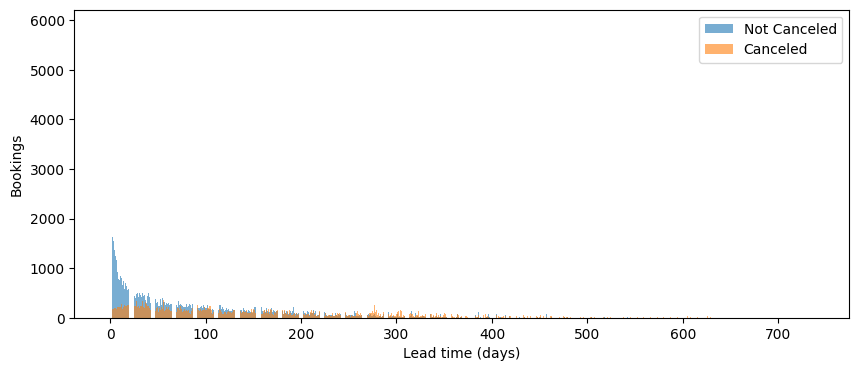

In [231]:
p = lt.pivot(index="lead_time", columns="is_canceled", values="count").fillna(0)

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(p.index, p[0], alpha=0.6, label="Not Canceled")
ax.bar(p.index, p[1], alpha=0.6, label="Canceled")
ax.set_xlabel("Lead time (days)")
ax.set_ylabel("Bookings")
ax.legend()
plt.show()

In [232]:
cg = cancelled.groupby(["lead_time"]).size().reset_index(name="count")
ng = not_cancelled.groupby(["lead_time"]).size().reset_index(name="count")

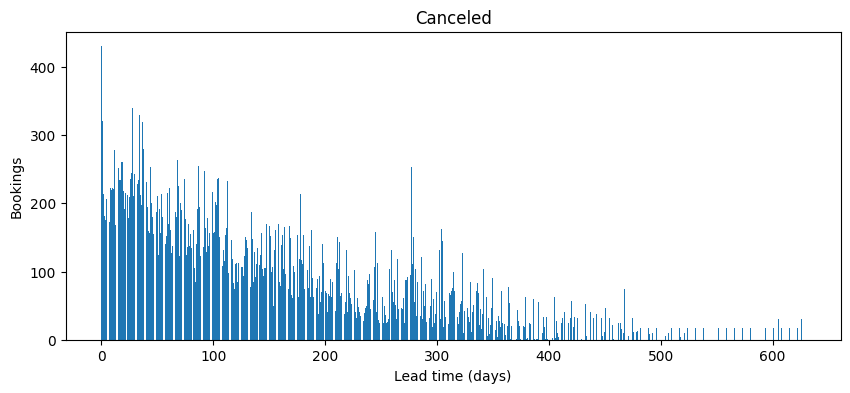

In [233]:
plt.figure(figsize=(10, 4))
plt.bar(cg["lead_time"], cg["count"])
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.title("Canceled")
plt.show()

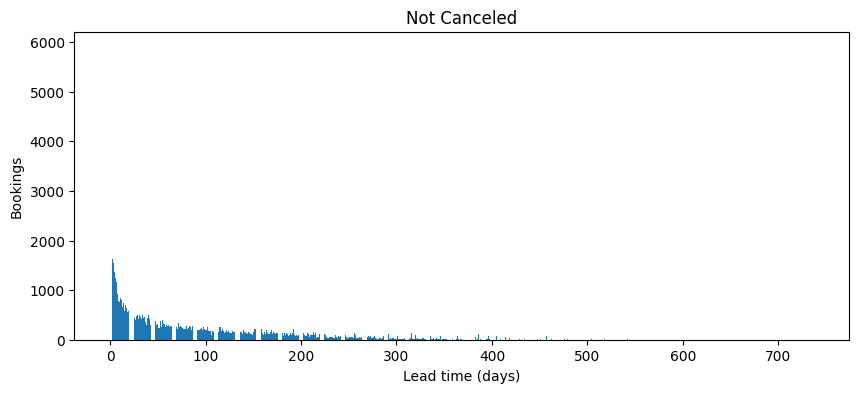

In [234]:
plt.figure(figsize=(10, 4))
plt.bar(ng["lead_time"], ng["count"])
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.title("Not Canceled")
plt.show()

There are some outliers for sure. I would first train one model with the outliers and then without. We need to analyse the outliers to see if we can remove then. If there are outliers in other variables and they all share the same row, we can safely delete those.

I'm not going to delete the outliers for now because i) they are few and ii) they belong to not canceled.

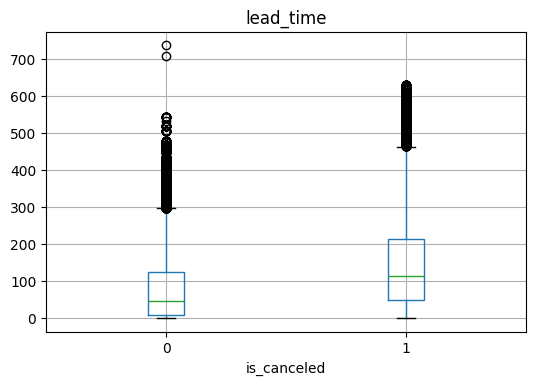

In [235]:
df.boxplot(column="lead_time", by="is_canceled", figsize=(6, 4))
plt.suptitle("")
plt.show()

There's some differences in the IQR between canceled and not canceled. The 1 quartile, median and third quartile are higher for 1 (canceled), together with the upper fence. Interesting. This means that the leadtime's distribution of canceled ones is higher, and so is the median and should be the mean.

We can infer that there's a "big" correlation between the lead_time and canceling and that people who cancels usually have a bigger leadtime. The bigger the leadtime, the more chances the person will cancel.


Let's check 'stay_in_weekends' variable:

In [236]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [237]:
df[["lead_time", "is_canceled"]].groupby(["is_canceled"]).mean()

,lead_time
is_canceled,
0,79.984687
1,144.848815


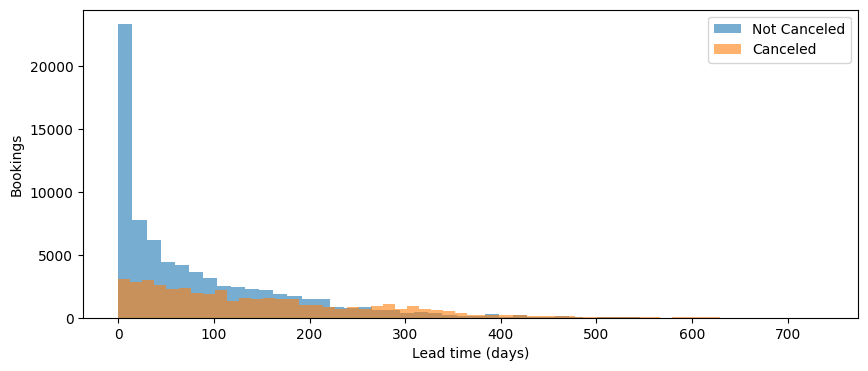

In [238]:
plt.figure(figsize=(10, 4))
plt.hist(not_cancelled["lead_time"], bins=50, alpha=0.6, label="Not Canceled")
plt.hist(cancelled["lead_time"], bins=50, alpha=0.6, label="Canceled")
plt.xlabel("Lead time (days)")
plt.ylabel("Bookings")
plt.legend()
plt.show()

In [239]:
scg = cancelled.groupby(["stays_in_weekend_nights"]).size().reset_index(name="count")
sng = not_cancelled.groupby(["stays_in_weekend_nights"]).size().reset_index(name="count")

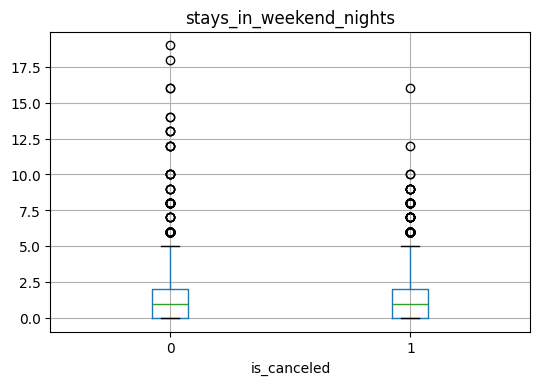

In [240]:
df.boxplot(column="stays_in_weekend_nights", by="is_canceled", figsize=(6, 4))
plt.suptitle("")
plt.show()

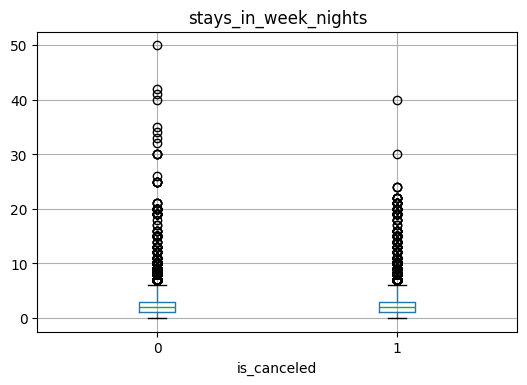

In [241]:
df.boxplot(column="stays_in_week_nights", by="is_canceled", figsize=(6, 4))
plt.suptitle("")
plt.show()

I'll leave the these as it is. It's weird, but ok for now. Let's analyse the other one:

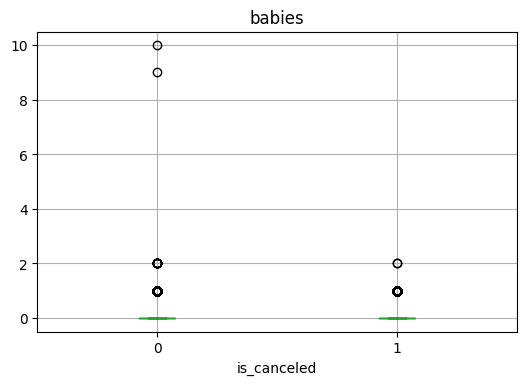

In [242]:
df.boxplot(column="babies", by="is_canceled", figsize=(6, 4))
plt.suptitle("")
plt.show()

Enough of outliers, nothing is too big to be deleted right away - I don't believe the outliers are system errors or anything, just random people that actually booked 40 nights, brought 10 babies and so on. And funny enough, the outliers didn't cancel, so apparently that actually happened.

We could see if all the outliers share outliers in different columns. If yes, removing some rows would be interesting. if not, we are risking losing real data in a significant way.

## Handling Nan

In [243]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [244]:
df["company"].isnull().sum()

np.int64(112593)

In [245]:
df["test"] = df.groupby('is_canceled')['lead_time'].transform('median')

In [246]:
df["test"].value_counts()

,count
test,
45.0,75166
113.0,44224


In [247]:
df.groupby('is_canceled')['lead_time'].median()

,lead_time
is_canceled,
0,45.0
1,113.0


In [248]:
df.groupby(["is_canceled"]).count()

,hotel,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,...,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date,test
is_canceled,,,,,,,,,,,,,,,,,,,,,
0,75166,75166,75166,75166,75166,75166,75166,75166,75166,75166,...,62856,5606,75166,75166,75166,75166,75166,75166,75166,75166
1,44224,44224,44224,44224,44224,44224,44224,44224,44224,44220,...,40194,1191,44224,44224,44224,44224,44224,44224,44224,44224


For NaN, we will handle each case accordingly. Let's start with Children. It's only 4 cases where is NaN. Let's remove these from the model, easier. Country, we will fill the NaNs with 'Empty' and then one hot encode them. Let's see if there's a correlation between the country and is_canceled. Probably not. We will problably see noise and Portugal leading all because the hotels are in Portugal. I don't think the NaNs in country belong more to the canceled ones, but we will check.

In [249]:
print(f"Df countries NAN: {df["country"].isna().sum()}")
print(f"Canceled countries NAN: {cancelled["country"].isna().sum()}")
print(f"Not Canceled countries NAN: {not_cancelled["country"].isna().sum()}")
print(f"Proportion:{not_cancelled["country"].isna().sum()/df["country"].isna().sum()}")

Df countries NAN: 488
Canceled countries NAN: 67
Not Canceled countries NAN: 421
Proportion:0.8627049180327869


In [250]:
print(f"Len DF: {len(df)}")
print(f"Len cancelled: {len(cancelled)}")
print(f"Len not cancelled: {len(not_cancelled)}")
print(f"Len DF: {len(not_cancelled)/len(df)}")

Len DF: 119390
Len cancelled: 44224
Len not cancelled: 75166
Len DF: 0.6295837172292487


There is a difference here. 86% of the bookings with no country were not cancelled, compared with 63% across all bookings. So a missing country is linked to a lower chance of cancelling. It's only 488 rows, so the effect on the model is small, but it's not random noise. We will keep these rows and fill the NaNs, so the model can use "no country" as a signal.

Agent we will handle similar, we will replace the Nulls for 'individual', assuming that when the agent is null, the client didn't use an agency to book the stay.

Same goes for company. We will fill 'individual'.

In [251]:
print(df['children'].isna().sum())
print(len(df))
print(len(df['children'].dropna()))

4
119390
119386


I was going to insert 'individual' for Null values in agent and company. Then, I was going to replace all other values for 'agent', and we would have a binary column at the end. However, since we have 333 unique agencies, there might exist a correlation between the cancelation and the agents - maybe some agencies cancel more ofter. We will need to explore that before doing that.

In [252]:
df['agent'].dropna().sort_values()

,agent
81343,1.0
81318,1.0
81317,1.0
81316,1.0
81308,1.0
...,...
12638,531.0
12392,531.0
37346,535.0
37370,535.0


In [253]:
len(df['agent'].dropna().unique())
# df['agent'].fillna("individual")

333

In [254]:
cancelled.groupby("agent").size().sort_values(ascending=False).head(10).reset_index(name="count")

,agent,count
0,9.0,13264
1,240.0,5484
2,1.0,5280
3,6.0,1025
4,19.0,780
5,3.0,771
6,37.0,717
7,14.0,652
8,29.0,546
9,250.0,513


In [255]:
not_cancelled.groupby("agent").size().sort_values(ascending=False).head(10).reset_index(name="count")

,agent,count
0,9.0,18697
1,240.0,8438
2,7.0,3065
3,14.0,2988
4,250.0,2357
5,6.0,2265
6,1.0,1911
7,28.0,1556
8,241.0,1485
9,8.0,1087


In [256]:
df.groupby("agent").size().sort_values(ascending=False).head(10).reset_index(name="count")

,agent,count
0,9.0,31961
1,240.0,13922
2,1.0,7191
3,14.0,3640
4,7.0,3539
5,6.0,3290
6,250.0,2870
7,241.0,1721
8,28.0,1666
9,8.0,1514


Interesting, some agencies have more canceled because they did more bookings - then it's fine and noise - but some apparently (like 193, 37, 29) may get more cancellations than others.

In [257]:
print(f"DF: {df.groupby("agent").size().reset_index(name="count").query("agent==37.0")}")
print(f"Cancelled : {cancelled.groupby("agent").size().reset_index(name="count").query("agent==37.0")}")
print(f"Not Cancelled: {not_cancelled.groupby("agent").size().reset_index(name="count").query("agent==37.0")}")

DF:     agent  count
35   37.0   1230
Cancelled :     agent  count
33   37.0    717
Not Cancelled:     agent  count
35   37.0    513


Cool, the agency might be a driver. In 37, more than half of the bookings realized were cancelled. Our initial idea of replacing them all is not good. We will do the same for the countries them, we will fill the NaNs with a code. This is not ideal, because the model might infer things that are not there, so I'll change it from float to string (object) and then one hot encode as well. It's better, I don't know why an ID should be a number.

In [258]:
# This is the cancelation rate per agent. We are interested in the not 1 nor 0 ones.

df.groupby("agent")["is_canceled"].mean().sort_values(ascending=False)

,is_canceled
agent,
41.0,1.0
403.0,1.0
236.0,1.0
472.0,1.0
492.0,1.0
...,...
467.0,0.0
510.0,0.0
469.0,0.0


In [259]:
df["agent"] = df["agent"].astype(str)
df['agent'].fillna("individual") # didn't work now
df["agent"] = df["agent"].replace("nan", "individual")

In [260]:
df["agent"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: agent
Non-Null Count   Dtype 
--------------   ----- 
119390 non-null  object
dtypes: object(1)
memory usage: 932.9+ KB


In [261]:
# Let's do the same for company
df["company"] = df["company"].astype(str)
df["company"] = df["company"].replace("nan", "individual")

In [262]:
df["company"].info()

<class 'pandas.core.series.Series'>
RangeIndex: 119390 entries, 0 to 119389
Series name: company
Non-Null Count   Dtype 
--------------   ----- 
119390 non-null  object
dtypes: object(1)
memory usage: 932.9+ KB


In [263]:
df["company"].value_counts()

,count
company,
individual,112593
40.0,927
223.0,784
67.0,267
45.0,250
...,...
18.0,1
273.0,1
368.0,1


In [264]:
len(df["company"].unique().sum())

1708

This will not work well for company I guess. Let's check. I think company we can have 'company' and 'individual' only. Easier, simpler, might avoid overfitting.

In [265]:
df.groupby("company").size().sort_values(ascending=False).head(10).reset_index(name="count")

,company,count
0,individual,112593
1,40.0,927
2,223.0,784
3,67.0,267
4,45.0,250
5,153.0,215
6,174.0,149
7,219.0,141
8,281.0,138
9,154.0,133


In [266]:
cancelled.groupby("company").size().sort_values(ascending=False).head(10).reset_index(name="count")

,company,count
0,67.0,175
1,223.0,119
2,40.0,77
3,348.0,59
4,153.0,48
5,202.0,38
6,51.0,35
7,197.0,35
8,385.0,30
9,45.0,28


In [267]:
not_cancelled.groupby("company").size().sort_values(ascending=False).head(10).reset_index(name="count")

,company,count
0,40.0,850
1,223.0,665
2,45.0,222
3,153.0,167
4,219.0,132
5,174.0,128
6,154.0,128
7,281.0,121
8,233.0,103
9,405.0,101


Yeah, actually, same case for the agent. Company '67' had more cancellations than shows. Let leave as it is and test it.

## Comparing the dates Canceled x not Canceled

In [268]:
cancelled.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date'],
      dtype='object')

In [269]:
cy = cancelled.groupby("arrival_date_year").size().reset_index(name="count")
ny = not_cancelled.groupby("arrival_date_year").size().reset_index(name="count")
dy = df.groupby("arrival_date_year").size().reset_index(name="count")

cm = cancelled.groupby("arrival_date_month").size().reset_index(name="count")
nm = not_cancelled.groupby("arrival_date_month").size().reset_index(name="count")
dm = df.groupby("arrival_date_month").size().reset_index(name="count")

cw = cancelled.groupby("arrival_date_week_number").size().reset_index(name="count")
nw = not_cancelled.groupby("arrival_date_week_number").size().reset_index(name="count")
dw = df.groupby("arrival_date_week_number").size().reset_index(name="count")

cd = cancelled.groupby("arrival_date_day_of_month").size().reset_index(name="count")
nd = not_cancelled.groupby("arrival_date_day_of_month").size().reset_index(name="count")
dd = df.groupby("arrival_date_day_of_month").size().reset_index(name="count")

In [270]:
dy

,arrival_date_year,count
0,2015,21996
1,2016,56707
2,2017,40687


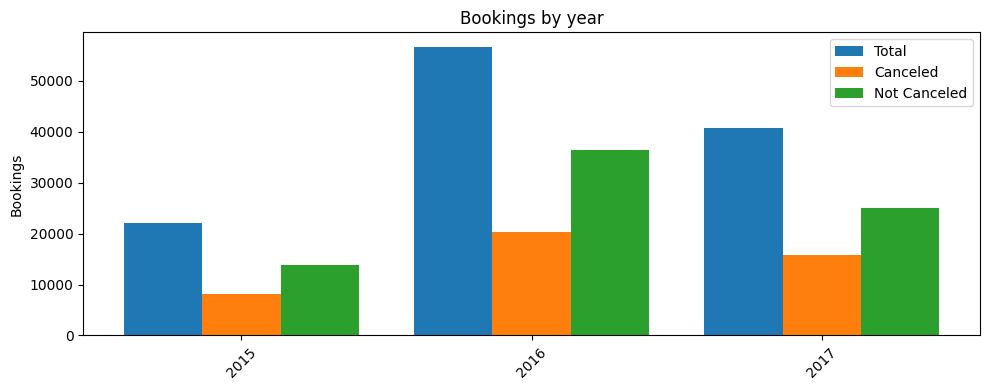

In [271]:
grouped_bar(dy, cy, ny, "arrival_date_year", title="Bookings by year")

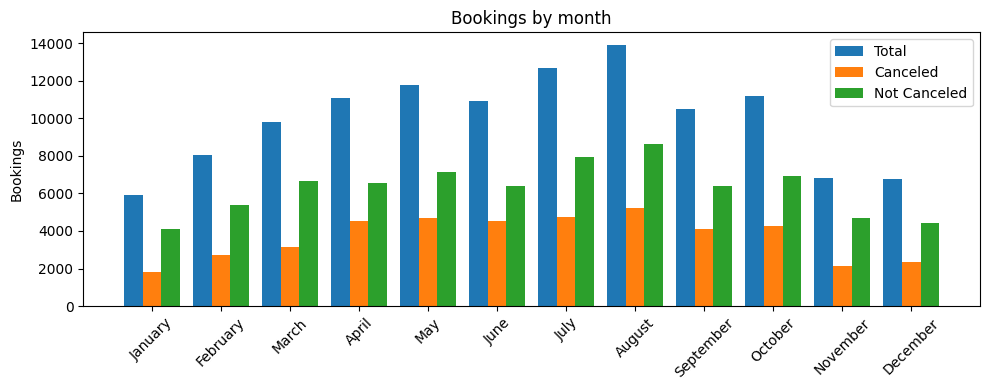

In [272]:
months = ["January", "February", "March", "April", "May", "June",
          "July", "August", "September", "October", "November", "December"]

grouped_bar(dm, cm, nm, "arrival_date_month", order=months, title="Bookings by month")

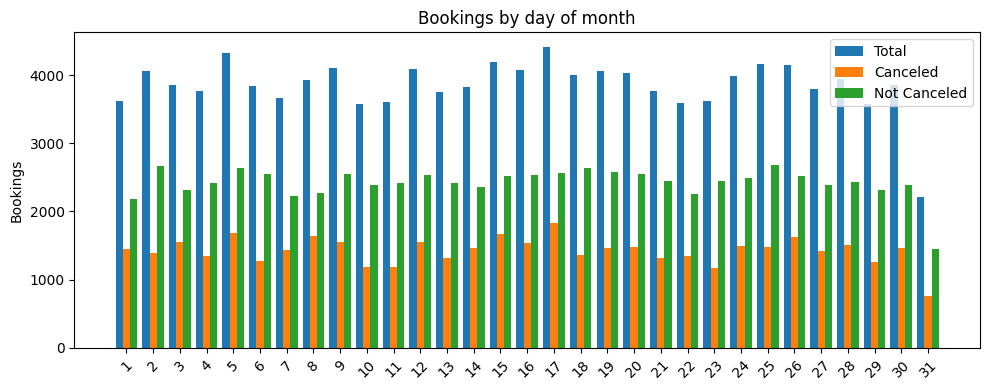

In [273]:
grouped_bar(dd, cd, nd, "arrival_date_day_of_month", title="Bookings by day of month")

Everything seem pretty steady. Nothing I can take from this at first. Some months have more chance that getting a cancellation apparently.

## Exploring correlations -> One Hot Enconding

In [274]:
# Let's check the variables that have the biggest correlation with our target. Only the numerical ones for now:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 33 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  object 
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  object 
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal            

In [275]:
cor = df.select_dtypes(include=[float, int]).corr()
print(cor["is_canceled"].sort_values(ascending=False))

is_canceled                       1.000000
test                              1.000000
lead_time                         0.293123
previous_cancellations            0.110133
adults                            0.060017
days_in_waiting_list              0.054186
adr                               0.047557
stays_in_week_nights              0.024765
arrival_date_year                 0.016660
arrival_date_week_number          0.008148
children                          0.005048
stays_in_weekend_nights          -0.001791
arrival_date_day_of_month        -0.006130
babies                           -0.032491
previous_bookings_not_canceled   -0.057358
is_repeated_guest                -0.084793
booking_changes                  -0.144381
required_car_parking_spaces      -0.195498
total_of_special_requests        -0.234658
Name: is_canceled, dtype: float64


In [276]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'test'],
      dtype='object')

In [277]:
temp = df.drop(["reservation_status", "reservation_status_date"], axis=1)
cat = pd.get_dummies(temp.select_dtypes(include=[object])) # need to "clean" the data first - this is just to get an idea

In [278]:
target = df["is_canceled"]
cat_f = pd.merge(target, cat, left_index=True, right_index=True)

In [279]:
# cat_cor = cat_f.corr()
# cat_cor["is_canceled"].sort_values(ascending=False)

Very interesting, and it makes a lot of sense. The deposit type is the most correletaed variable, followed by the country (I imagine people that book a hotel from overseas tend to cancel less). Some surprises as well, like the 'market_segment_Groups'. Cool. For this first try, we will only take into consideration variables with correlation >0.1 or <0.1.

But before, let's play a little bit with the numerical ones to see if we can increase the correlation.

## Feature Engineering

In [280]:
df.select_dtypes(include=[float, int]).head()

,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,booking_changes,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests,test
0,0,342,2015,27,1,0,0,2,0.0,0,0,0,0,3,0,0.0,0,0,45.0
1,0,737,2015,27,1,0,0,2,0.0,0,0,0,0,4,0,0.0,0,0,45.0
2,0,7,2015,27,1,0,1,1,0.0,0,0,0,0,0,0,75.0,0,0,45.0
3,0,13,2015,27,1,0,1,1,0.0,0,0,0,0,0,0,75.0,0,0,45.0
4,0,14,2015,27,1,0,2,2,0.0,0,0,0,0,0,0,98.0,0,1,45.0


In [281]:
df["arrival_date_month"].unique()

array(['July', 'August', 'September', 'October', 'November', 'December',
       'January', 'February', 'March', 'April', 'May', 'June'],
      dtype=object)

In [282]:
from datetime import datetime

# Example with the standard date and time format
date_format = '%d/%m/%Y'

# Let's start with "Party number", where we will sum the total number of people for the booking
df["Party Number"] = df["adults"] + df["children"] + df["babies"]

# Now, let's see if the date of booking has an impact
df["arrival_date_month_number"] = df["arrival_date_month"].replace({'July': "07", 'August': "08", 'September': "09", 'October': "10", 'November': "11", 'December': "12",
       'January': "01", 'February': "02", 'March': "03", 'April': "04", 'May': "05", 'June': "06"})

df["arrival_date_datetime_string"] = df["arrival_date_day_of_month"].map(str) + "/" + df["arrival_date_month_number"].map(str) + "/" + df["arrival_date_year"].map(str)

df["arrival_date_datetime"] = pd.to_datetime(df["arrival_date_datetime_string"], format="%d/%m/%Y")

In [283]:
df["booking_date_datetime"] = df["arrival_date_datetime"] - pd.to_timedelta(df["lead_time"], unit="D")

In [284]:
df[["arrival_date_datetime_string", "booking_date_datetime", "lead_time"]].head()

,arrival_date_datetime_string,booking_date_datetime,lead_time
0,1/07/2015,2014-07-24,342
1,1/07/2015,2013-06-24,737
2,1/07/2015,2015-06-24,7
3,1/07/2015,2015-06-18,13
4,1/07/2015,2015-06-17,14


In [285]:
df["booking_year"] = df["booking_date_datetime"].dt.year
df["booking_month"] = df["booking_date_datetime"].dt.month
df["booking_dayofweek"] = df["booking_date_datetime"].dt.dayofweek

In [286]:
df["Party Number"].head()

,Party Number
0,2.0
1,2.0
2,1.0
3,1.0
4,2.0


In [287]:
# Let's see if these new variables changed something:
new_num_cor = df.select_dtypes([float, int]).corr()
new_num_cor["is_canceled"].sort_values(ascending=False)

,is_canceled
is_canceled,1.000000
test,1.000000
lead_time,0.293123
previous_cancellations,0.110133
adults,0.060017
days_in_waiting_list,0.054186
booking_month,0.050502
adr,0.047557
Party Number,0.046506
booking_dayofweek,0.034071


Apparently, just the year of the booking had a higher correlation - but this is irrelevant as well if we think we want to create a model to predict the future. It's possible that a year usually has more cancelleations than other and the model can pick on that, but I don't think that's likely.

## Other variables

In [288]:
# Let's take a quick look on other columns now:
for c in df.columns:
  print(df[c].value_counts(dropna=False))

hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64
is_canceled
0    75166
1    44224
Name: count, dtype: int64
lead_time
0      6345
1      3460
2      2069
3      1816
4      1715
       ... 
435       1
532       1
371       1
380       1
463       1
Name: count, Length: 479, dtype: int64
arrival_date_year
2016    56707
2017    40687
2015    21996
Name: count, dtype: int64
arrival_date_month
August       13877
July         12661
May          11791
October      11160
April        11089
June         10939
September    10508
March         9794
February      8068
November      6794
December      6780
January       5929
Name: count, dtype: int64
arrival_date_week_number
33    3580
30    3087
32    3045
34    3040
18    2926
21    2854
28    2853
17    2805
20    2785
29    2763
42    2756
31    2741
41    2699
15    2689
27    2664
25    2663
38    2661
23    2621
35    2593
39    2581
22    2546
24    2498
13    2416
16    2405
19    2402
40    2397
26    2391
43

In [289]:
# Let's check adr
df["adr"].describe()

,adr
count,119390.000000
mean,101.831122
std,50.535790
min,-6.380000
25%,69.290000
50%,94.575000
75%,126.000000
max,5400.000000


Just as a reminder, adr is the "Average Daily Rate as defined by dividing the sum of all lodging transactions by the total number of staying nights".

This is the price per night.

In [290]:
print(f"Average price per night canceled x not canceled: {df[["adr", "is_canceled"]].groupby("is_canceled").mean()}")

Average price per night canceled x not canceled:                     adr
is_canceled            
0             99.987693
1            104.964333


People that cancels spend more per night on average. But that might be outliers as well.

In [291]:
print(f"STD price per night canceled x not canceled: {df[["adr", "is_canceled"]].groupby("is_canceled").std()}")

STD price per night canceled x not canceled:                    adr
is_canceled           
0            49.206263
1            52.571142


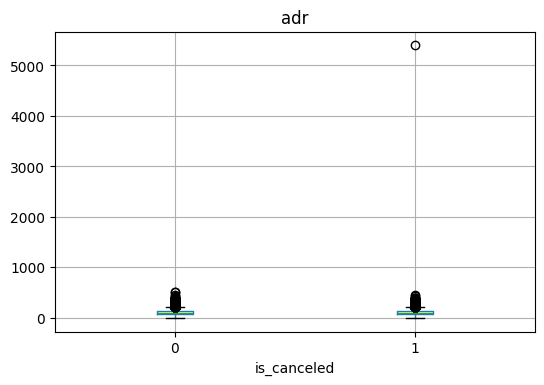

In [292]:
df.boxplot(column="adr", by="is_canceled", figsize=(6, 4))
plt.suptitle("")
plt.show()

In [293]:
df.loc[df['adr'] > 5000]["adr"]

,adr
48515,5400.0


In [294]:
i = df[df["adr"] > 5000.0 ].index
i

Index([48515], dtype='int64')

In [295]:
# Let's remove these
print(f"before: {df.shape}")
indices_to_drop = (df[df['adr'] < 0].index)
print(f"Indices to drop: {indices_to_drop}")
df.drop(indices_to_drop, inplace=True)
df.drop(48515, inplace=True)
print(f"after: {df.shape}")

before: (119390, 41)
Indices to drop: Index([14969], dtype='int64')
after: (119388, 41)


In [296]:
# Column is_canceled x reservation_status
df.groupby(["reservation_status", "is_canceled"]).size()

# Is the same column, since the target is 'is_canceled', we can't ignore the other one

,,0
reservation_status,is_canceled,
Canceled,1,43016
Check-Out,0,75165
No-Show,1,1207


## Prepare the dataset for the model

In [297]:
# Let's use Logistic Regression for this

# Logistic Regression is a supervised machine learning algorithm used for
# classification problems. Unlike linear regression, which predicts continuous
# values it predicts the probability that an input belongs to a specific class.

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

In [298]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'test', 'Party Number',
       'arrival_date_month_number', 'arrival_date_datetime_string',
       'arrival_date_datetime', 'booking_date_datetime', 'booking_year',
       'booking_month', 'booking_dayofweek'],
      dtype='object')

In [299]:
cor = df.select_dtypes(include=[float, int]).corr()
print(abs(cor["is_canceled"].sort_values(ascending=False)) > 0.1)

is_canceled                        True
test                               True
lead_time                          True
previous_cancellations             True
adults                            False
days_in_waiting_list              False
booking_month                     False
adr                               False
Party Number                      False
booking_dayofweek                 False
stays_in_week_nights              False
arrival_date_year                 False
arrival_date_week_number          False
children                          False
stays_in_weekend_nights           False
arrival_date_day_of_month         False
babies                            False
previous_bookings_not_canceled    False
is_repeated_guest                 False
booking_year                       True
booking_changes                    True
required_car_parking_spaces        True
total_of_special_requests          True
Name: is_canceled, dtype: bool


In [300]:
# cat_cor = cat_f.corr()
# print(
#     cat_cor["is_canceled"][
#         abs(cat_cor["is_canceled"]) > 0.1
#     ].sort_values(key=abs, ascending=False)
# )

In [301]:
cat_f

,is_canceled,hotel_City Hotel,hotel_Resort Hotel,arrival_date_month_April,arrival_date_month_August,arrival_date_month_December,arrival_date_month_February,arrival_date_month_January,arrival_date_month_July,arrival_date_month_June,...,company_92.0,company_93.0,company_94.0,company_96.0,company_99.0,company_individual,customer_type_Contract,customer_type_Group,customer_type_Transient,customer_type_Transient-Party
0,0,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
1,0,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
2,0,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
3,0,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
4,0,False,True,False,False,False,False,False,True,False,...,False,False,False,False,False,True,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,0,True,False,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
119386,0,True,False,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
119387,0,True,False,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
119388,0,True,False,False,True,False,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False


In [302]:
for c in cat_f.columns:
  if c.startswith("agent"):
    print(c)

agent_1.0
agent_10.0
agent_103.0
agent_104.0
agent_105.0
agent_106.0
agent_107.0
agent_11.0
agent_110.0
agent_111.0
agent_112.0
agent_114.0
agent_115.0
agent_117.0
agent_118.0
agent_119.0
agent_12.0
agent_121.0
agent_122.0
agent_126.0
agent_127.0
agent_128.0
agent_129.0
agent_13.0
agent_132.0
agent_133.0
agent_134.0
agent_135.0
agent_138.0
agent_139.0
agent_14.0
agent_141.0
agent_142.0
agent_143.0
agent_144.0
agent_146.0
agent_147.0
agent_148.0
agent_149.0
agent_15.0
agent_150.0
agent_151.0
agent_152.0
agent_153.0
agent_154.0
agent_155.0
agent_156.0
agent_157.0
agent_158.0
agent_159.0
agent_16.0
agent_162.0
agent_163.0
agent_165.0
agent_167.0
agent_168.0
agent_17.0
agent_170.0
agent_171.0
agent_173.0
agent_174.0
agent_175.0
agent_177.0
agent_179.0
agent_180.0
agent_181.0
agent_182.0
agent_183.0
agent_184.0
agent_185.0
agent_187.0
agent_19.0
agent_191.0
agent_192.0
agent_193.0
agent_195.0
agent_196.0
agent_197.0
agent_2.0
agent_20.0
agent_201.0
agent_205.0
agent_208.0
agent_21.0
agent_2

In [303]:
# Let's use only features with a higer | 0.1 | correlation for now only. The numerical ones:
X_num = df.select_dtypes([float, int]).drop(["adults", "days_in_waiting_list", "adr", "Party Number", "stays_in_week_nights",
             "booking_month", "booking_dayofweek", "arrival_date_week_number",
             "children",  "stays_in_weekend_nights", "arrival_date_day_of_month",  "babies",
             "previous_bookings_not_canceled", "is_repeated_guest"], axis=1)

X_cat = cat_f[[
    "deposit_type_Non Refund",
    "deposit_type_No Deposit",
    "country_PRT",
    "market_segment_Groups",
    "assigned_room_type_A",
    "agent_1.0",
    "distribution_channel_TA/TO",
    "market_segment_Direct",
    "distribution_channel_Direct",
    "hotel_City Hotel",
    "hotel_Resort Hotel",
    "customer_type_Transient",
    "assigned_room_type_D",
    "customer_type_Transient-Party",
    "country_FRA",
    "country_GBR",
    "country_DEU",
    "agent_individual"
]]

# The categorical ones:
X = pd.merge(X_num, X_cat, left_index=True, right_index=True)
X = X.drop(["is_canceled", "test", "booking_year"], axis=1)

Y = df["is_canceled"]

I forgot to remove the target from X at first, and the train and test data got 100% accuracy. This is called target leakage. And it looks like "too good to be true" on both.

Also, for every variable, we need to ask the following question: Would I know this at the moment the booking is made? If no, we need to remove it. At first, I didn't remove assigned_room_type and country, but depending on the business, this information might only happen in the checkout. In fact, let's check if there're only NaNs in the canceled dataset for countries. If yes, we can remove it because it will show that this information might be only collected in the check in (I don't think so though).

In [304]:
cancelled["country"].unique()

array(['PRT', 'IRL', 'ESP', 'DEU', 'CN', 'ITA', nan, 'GBR', 'FRA', 'ARE',
       'BRA', 'NLD', 'FIN', 'CHE', 'TUN', 'BEL', 'USA', 'ARG', 'NOR',
       'CHN', 'POL', 'DNK', 'ALB', 'RUS', 'SWE', 'AUT', 'HKG', 'IND',
       'CZE', 'LUX', 'GEO', 'DZA', 'MAR', 'AND', 'ROU', 'TUR', 'MOZ',
       'ZAF', 'GIB', 'AUS', 'URY', 'BLR', 'JEY', 'CYP', 'EST', 'ISR',
       'GRC', 'LVA', 'COL', 'GGY', 'KWT', 'NGA', 'KOR', 'CHL', 'HUN',
       'HRV', 'MDV', 'VEN', 'SVK', 'AGO', 'FJI', 'KAZ', 'PAK', 'IDN',
       'SVN', 'LBN', 'PHL', 'LTU', 'SEN', 'SYC', 'AZE', 'BHR', 'IRN',
       'SAU', 'UKR', 'ECU', 'OMN', 'CPV', 'THA', 'TWN', 'HND', 'SRB',
       'JPN', 'SGP', 'MEX', 'ZMB', 'QAT', 'NZL', 'KHM', 'MCO', 'BGD',
       'UZB', 'BGR', 'IMN', 'TJK', 'ARM', 'PER', 'NIC', 'ISL', 'BEN',
       'MAC', 'VGB', 'MUS', 'MLT', 'EGY', 'CRI', 'TZA', 'JOR', 'MYS',
       'GAB', 'MKD', 'BIH', 'VNM', 'GHA', 'TMP', 'GLP', 'KEN', 'PRI',
       'DOM', 'LIE', 'GNB', 'ETH', 'MNE', 'UMI', 'MYT', 'FRO', 'CIV',
       'ZWE'], d

Apparently the country is filled before check in, we don't need to remove it.

In [305]:
X

,lead_time,arrival_date_year,previous_cancellations,booking_changes,required_car_parking_spaces,total_of_special_requests,deposit_type_Non Refund,deposit_type_No Deposit,country_PRT,market_segment_Groups,...,distribution_channel_Direct,hotel_City Hotel,hotel_Resort Hotel,customer_type_Transient,assigned_room_type_D,customer_type_Transient-Party,country_FRA,country_GBR,country_DEU,agent_individual
0,342,2015,0,3,0,0,False,True,True,False,...,True,False,True,True,False,False,False,False,False,True
1,737,2015,0,4,0,0,False,True,True,False,...,True,False,True,True,False,False,False,False,False,True
2,7,2015,0,0,0,0,False,True,False,False,...,True,False,True,True,False,False,False,True,False,True
3,13,2015,0,0,0,0,False,True,False,False,...,False,False,True,True,False,False,False,True,False,False
4,14,2015,0,0,0,1,False,True,False,False,...,False,False,True,True,False,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
119385,23,2017,0,0,0,0,False,True,False,False,...,False,True,False,True,False,False,False,False,False,False
119386,102,2017,0,0,0,2,False,True,False,False,...,False,True,False,True,False,False,True,False,False,False
119387,34,2017,0,0,0,4,False,True,False,False,...,False,True,False,True,True,False,False,False,True,False
119388,109,2017,0,0,0,0,False,True,False,False,...,False,True,False,True,False,False,False,True,False,False


In [306]:
# Instead of dividing the train and test randomly, let's divide it using the years. We will train the model on 2015 and 2016, and try to predict 2017. For that,
# we won't need stratify or random_state - they only apply to random splits. We also had to remove booking_year from the training.

years = X.loc[X.index, "arrival_date_year"]

train_mask = years < 2017
test_mask = years == 2017

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = Y[train_mask], Y[test_mask]

#X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.20, random_state=42) - we don't need that anymore.

In [307]:
clf = LogisticRegression(max_iter=10000, random_state=42) # Training converges slowly or badly when features are on very different scales. That's why we need max_iter
clf.fit(X_train, y_train)

LogisticRegression(max_iter=10000, random_state=42)

In [308]:
acc = accuracy_score(y_test, clf.predict(X_test)) * 100
print(f"Logistic Regression model accuracy: {acc:.2f}%")

Logistic Regression model accuracy: 74.63%


In [309]:
clf.score(X_train, y_train)

0.8032451526009504

Since we have 63% accuracy as a baseline (a model that perdicts 'not cancelled' for everything would get 63% of the data right), the model need to perform above it on accuracy.

In [310]:
clf.score(X_test, y_test)

0.7462517819397335

In [311]:
y_pred = clf.predict(X_test)

In [312]:
from sklearn.metrics import confusion_matrix, classification_report
print(confusion_matrix(y_test, y_pred))

[[23322  1619]
 [ 8705  7040]]


Here, the model correctly predicted that 23322 would show up and they did (True Negative, the model predicted 0 correctly). 1619 were wrong: the model said they would cancel and they didn't (it predicted 1, they were in fact 0). It's less problematic for this business purpose, because we are trying to avoid people to cancel. Worst case scenario here we would send an offer/message to someone that wasn't going to cancel anyway.

8705 is the problem. The model said these people would come, and they actually canceled. We want this number as low as possible. 7040 the model said they would cancel and they truly did.

If the problem was overbooking, then the worst number would be 1619, because we assumed they would cancel and we might have opened the room for other guests and they came in the end.

In [313]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.94      0.82     24941
           1       0.81      0.45      0.58     15745

    accuracy                           0.75     40686
   macro avg       0.77      0.69      0.70     40686
weighted avg       0.76      0.75      0.73     40686



- Accuracy = correct / total. This is misleading with imbalance, which is why we need to compare it to the 63% baseline.
- Precision = TP / (TP + FP). How often is the model right in predicting 1 and 0. "When I say it'll cancel, how often am I right?"
- Recall = TP / (TP + FN). "Of all real cancellations, how many did I catch?" Only 45%, which is bad.
- F1 = a balance of precision and recall. Use it when you care about both.
- ROC AUC: how well the model ranks cancellations above non-cancellations, across all thresholds. 0.5 is random and 1.0 is perfect.

Model improvements:
- No scaling. Logistic regression is sensitive to scale. lead_time goes up to 737 while dummies are 0/1. Needing max_iter=10000 was a symptom of this.

- Only accuracy. 63% of bookings aren't cancelled, so a model that always says "not cancelled" already gets 63%. Always show this baseline, plus the confusion matrix and precision/recall.

- Feature selection using all the data. You picked features by correlation before splitting, so the test data influenced your choices. It's a small leak, but mention you know about it.

- We can add stratify. it will keep ~37% cancelled in both train and test, making sure train and test have the same share of cancellations.

In [314]:
# Logistic regression has to learn one weight for each feature. Scaling helps in two ways.
# Reason 1: training works better: The model learns by taking small steps to adjust all the weights. It uses one step size for every weight.
# Reason 2: the penalty becomes fair: By default, logistic regression adds a small penalty for big weights, to avoid overfitting.
# special_requests (0 to 5) needs a big weight to have any effect.
# lead_time (0 to 737) only needs a tiny weight.

I decided to scale because logistic regression is trained step by step with a penalty on weights. Features on different ranges make training slow and the penalty unfair. Scaling puts them on equal footing, and it also lets me compare coefficients.

Needs scaling: logistic regression, KNN, SVM, neural networks.
Doesn't need it: decision trees, random forest, XGBoost. Trees split on thresholds like "lead_time > 100", so scale doesn't matter.

When to use stratify:
Classification: yes, basically always. It costs nothing and keeps the class balance the same in train and test. It matters even more when the data is very imbalanced (like fraud at 1%).
Regression: no. There are no classes to balance.
Time-based split: no. There you split by date instead.

In [315]:
from sklearn.preprocessing import StandardScaler

#X_train, X_test, y_train, y_test = train_test_split(X,Y, test_size=0.20, random_state=42, stratify=df["is_canceled"])

years = X.loc[X.index, "arrival_date_year"]

train_mask = years < 2017
test_mask = years == 2017

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = Y[train_mask], Y[test_mask]

# 3. Scale. Fit on train only, then apply the same scaling to test
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# scale formula: scaled value = (value − mean) / std -> that's why we need the mean and std in fit_transform x transform

clf = LogisticRegression(max_iter=1000)
clf.fit(X_train_s, y_train)

print(clf.score(X_train_s, y_train))
print(clf.score(X_test_s, y_test))

0.8025209016289294
0.7460305756279801


In [316]:
# 5. Evaluate
y_pred = clf.predict(X_test_s)
print("Baseline:", round(1 - y_test.mean(), 3))
print("Train acc:", round(clf.score(X_train_s, y_train), 3))
print("Test acc:", round(clf.score(X_test_s, y_test), 3))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Baseline: 0.613
Train acc: 0.803
Test acc: 0.746
[[20602  4339]
 [ 5994  9751]]
              precision    recall  f1-score   support

           0       0.77      0.83      0.80     24941
           1       0.69      0.62      0.65     15745

    accuracy                           0.75     40686
   macro avg       0.73      0.72      0.73     40686
weighted avg       0.74      0.75      0.74     40686



In [317]:
pd.Series(clf.coef_[0], index=X.columns).sort_values()

,0
required_car_parking_spaces,-3.876542
total_of_special_requests,-0.424828
agent_individual,-0.265424
country_DEU,-0.251310
customer_type_Transient-Party,-0.219602
booking_changes,-0.214009
country_FRA,-0.193761
country_GBR,-0.187151
agent_1.0,-0.134924
hotel_Resort Hotel,-0.080820


In [318]:
probs = clf.predict_proba(X_test_s)[:, 1]   # probability of cancel -> with the [:, 1], we get only the second column (the probability of canceling)
y_pred_09 = (probs > 0.9).astype(int)       # stricter → higher precision, lower recall

In [319]:
probs

array([0.7793396 , 0.36607557, 0.36607557, ..., 0.03183592, 0.47499423,
       0.22573335])

In [320]:
y_pred_09

array([0, 0, 0, ..., 0, 0, 0])

In [321]:
# Probability of not canceling x Probability of canceling per input: [0.37975949 + 0.62024051] = 1
clf.predict_proba(X_test_s)

array([[0.2206604 , 0.7793396 ],
       [0.63392443, 0.36607557],
       [0.63392443, 0.36607557],
       ...,
       [0.96816408, 0.03183592],
       [0.52500577, 0.47499423],
       [0.77426665, 0.22573335]])

In [322]:
# Let's change the threshold: by default, Logistic Regression always uses 0.5:
print(confusion_matrix(y_test,y_pred_09 ))

[[24880    61]
 [11529  4216]]


It got way better for the overbooking problem and way worse for flagging the ones that will cancel.

In [323]:
print(classification_report(y_test, y_pred_09))

              precision    recall  f1-score   support

           0       0.68      1.00      0.81     24941
           1       0.99      0.27      0.42     15745

    accuracy                           0.72     40686
   macro avg       0.83      0.63      0.62     40686
weighted avg       0.80      0.72      0.66     40686



The model is very cautions. It almost always flags the canceled ones correclty, but it barely does that.

## Random Forest

Let's try another algorithm.

In [324]:
from sklearn.ensemble import RandomForestClassifier

# X_train, X_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y)

years = X.loc[X.index, "arrival_date_year"]

train_mask = years < 2017
test_mask = years == 2017

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = Y[train_mask], Y[test_mask]

rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)
rf_classifier.fit(X_train, y_train)

y_pred = rf_classifier.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print("--")
print(classification_report(y_test, y_pred))

[[20990  3951]
 [ 6742  9003]]
--
              precision    recall  f1-score   support

           0       0.76      0.84      0.80     24941
           1       0.69      0.57      0.63     15745

    accuracy                           0.74     40686
   macro avg       0.73      0.71      0.71     40686
weighted avg       0.73      0.74      0.73     40686



## XGBOOST

Last one.

In [325]:
import xgboost as xgb
from xgboost import XGBClassifier

In [326]:
# X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=42, stratify=Y, test_size=0.2)


years = X.loc[X.index, "arrival_date_year"]

train_mask = years < 2017
test_mask = years == 2017

X_train, X_test = X[train_mask], X[test_mask]
y_train, y_test = Y[train_mask], Y[test_mask]

params = {
    'objective':'binary:logistic',
    'max_depth':4,
    'learning_rate':0.1,
    'n_estimators':100,
    'alpha':10
}

xg = XGBClassifier(**params)
xg.fit(X_train, y_train)

y_pred = xg.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print("--")
print(classification_report(y_test, y_pred))

[[22358  2583]
 [ 6599  9146]]
--
              precision    recall  f1-score   support

           0       0.77      0.90      0.83     24941
           1       0.78      0.58      0.67     15745

    accuracy                           0.77     40686
   macro avg       0.78      0.74      0.75     40686
weighted avg       0.78      0.77      0.77     40686



In [327]:
df.columns

Index(['hotel', 'is_canceled', 'lead_time', 'arrival_date_year',
       'arrival_date_month', 'arrival_date_week_number',
       'arrival_date_day_of_month', 'stays_in_weekend_nights',
       'stays_in_week_nights', 'adults', 'children', 'babies', 'meal',
       'country', 'market_segment', 'distribution_channel',
       'is_repeated_guest', 'previous_cancellations',
       'previous_bookings_not_canceled', 'reserved_room_type',
       'assigned_room_type', 'booking_changes', 'deposit_type', 'agent',
       'company', 'days_in_waiting_list', 'customer_type', 'adr',
       'required_car_parking_spaces', 'total_of_special_requests',
       'reservation_status', 'reservation_status_date', 'test', 'Party Number',
       'arrival_date_month_number', 'arrival_date_datetime_string',
       'arrival_date_datetime', 'booking_date_datetime', 'booking_year',
       'booking_month', 'booking_dayofweek'],
      dtype='object')

In [328]:
df.groupby("is_canceled").size()

,0
is_canceled,
0,75165
1,44223


In [329]:
len(df)

119388

In [330]:
print(confusion_matrix(y_test, y_pred))

[[22358  2583]
 [ 6599  9146]]


In [331]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.77      0.90      0.83     24941
           1       0.78      0.58      0.67     15745

    accuracy                           0.77     40686
   macro avg       0.78      0.74      0.75     40686
weighted avg       0.78      0.77      0.77     40686



In [332]:
df2017 = df[df["arrival_date_year"] == 2017]
df2017[["adr", "is_canceled"]].groupby("is_canceled").mean()

,adr
is_canceled,
0,111.316755
1,119.906603


In [333]:
df2017["Total Nights"] = df2017["stays_in_week_nights"] + df2017["stays_in_weekend_nights"]
df2017[["Total Nights", "is_canceled"]].groupby("is_canceled").mean()

/tmp/ipykernel_1788/2790702751.py:1: SettingWithCopyWarning:


A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy



,Total Nights
is_canceled,
0,3.485386
1,3.716164


Out of all cancellations that happened in 2017 (15745), the model flagged correctly 9146, which is 58%. However, the model also said that 2583 people would cancel and they didn't.

Let's add some numbers. If a cancelation costs ~€480 to the hotel (that's how much they would spend per night * number of nights they would stay on average), so far in 2017 the hotel lost €480 * 15745 = €7.557.600 due to cancellations. And, if it costs €100 to send a reminder to each customer that will potentially cancel (and them either the customer doesn't cancel or let the hotel knows so it can free the room), then sending the reminder to all potential customers would cost 11729 (all people flagged as 'will cancel') * €100 = €1.172.900.

And, out of all messages sent, 9146 actually canceled. In the end, not counting how much it would cost to implement the solution and symplifing things A LOT, without the system, the hotel was losing €7.5M in sales. With the model, it will lose €7.557.600 - (€4.390.080) + €1.172.900 = €4.340.420 to cancelations, saving about €3.217.180.

## Conclusion

**Can we predict cancellations well enough to save the hotel money?** Yes, but not perfectly.

I would pick **XGBoost**. Trained on 2015–2016 and tested on 2017, it gets 77% accuracy, against a 61% baseline (always saying "not cancelled"). It also has the best precision (78%) and F1 (0.67) of all the models. In practice, it caught 9,146 of the 15,745 cancellations in 2017 (58%), with 2,583 false alarms.

The scaled Logistic Regression catches a few more cancellations (62%), but it gives almost twice as many false alarms (4,339). Since every false alarm costs money, XGBoost is the better balance.

**How much money?** In the best case, about €3.2M in 2017. This assumes every reminder sent to a real canceller saves the booking, which won't happen, so the real number is lower. It's still a sign that the model is worth testing.

**Main drivers of cancellation:** previous cancellations, non-refundable deposits, long lead times and Portuguese guests push cancellations up. Parking requests and special requests push them down.

**Next steps:** remove features the hotel wouldn't know at booking time (`assigned_room_type`, possibly `country`), add a realistic success rate to the money estimate, and choose the threshold that saves the most money, not the one with the best accuracy.